## The Drunkard's walk

- A drunken farmer is standing in the middle of a field, and every second
the farmer takes one step in a random direction. 

-  What is his expected distance from the origin in 1000 seconds?

- If he takes many steps:
    - is he likely to move ever farther from the origin, 
    - or is he more likely to wander back to the origin over and over, and end up
not far from where he started?

-  Let's write a simulation to find out.

- Let's develop some intuition 

- Let's start by sketching a simple model of the
situation using Cartesian coordinates
- assume that the farmer stands at the origin of a two-dimensional field $(0,0)$.
- Every second, the farmer takes one unit step, choosing north, south, east or west with equal probability.

![image info](onestep.png)

-  after one step he is always exactly one unit away from where he started. 

- Lets say he wanders eastward from his initial location on his first step
- How far away might he be from his initial location after his second
step?

![image info](twosteps.png)


-Therefore, the expected distance is
\begin{aligned}
\mathbb E[R_2]
&=\frac14(0)+\frac14(2)
  +\frac14\sqrt{2}+\frac14\sqrt{2}\\
&=\frac{1+\sqrt{2}}{2}\\
&\approx 1.207.
\end{aligned}

- After one step, the distance is exactly 1. 
- After two steps, the expected distance is approximately 1.207.

After $n$ steps, the farmer's position is
\begin{equation*}
(X_n,Y_n),
\end{equation*}
and the distance from the starting point is
\begin{equation*}
R_n=\sqrt{X_n^2+Y_n^2}.
\end{equation*}

- This suggests that the expected distance increases as the farmer takes more steps.
- But enumerating every possible walk becomes impractical as the number of steps increases.
- After $n$ steps, there are $4^n$ possible sequences of directions.

- That is our motivation for writing a simulation.

### Build the model using classes

#### three abstractions from the passage:
- `Location`: represents a position in the plane.
- `Field`: stores each drunkard's location and updates it.
- `UsualDrunk`: defines the four possible steps.

##### why we separate these responsibilities?.

- The benefit is that we can change the movement strategy later without rewriting the field or the simulation

In [1]:
import random
import math
import numpy as np

- First `class` `Location`
- A location represents the farmer's coordinates $(x,y)$.

In [37]:
class Location:
    def __init__(self, x, y):
        self.x = x
        self.y = y

    def __str__(self):
        return f"({self.x}, {self.y})"

    def move(self, dx, dy):
        return Location(self.x + dx, self.y + dy)

    def distance_from_origin(self):
        return math.sqrt(self.x**2 + self.y**2)

- Second `class` 'UsualDrunk'
- How does the farmer move?

In [38]:
class UsualDrunk:
    step_choices = [(1, 0), (-1, 0), (0, 1), (0, -1)]

    def take_step(self):
        return random.choice(self.step_choices)

In [9]:
farmer1 = UsualDrunk()
print(farmer1.take_step())

(1, 0)


- Third `class` `Field`
- separates where the farmer is from how the farmer moves.
- It keeps track of the farmer's current location and updates it after each step.
- This separation becomes particularly useful when simulating multiple farmers in the same field, each following a different movement strategy.

In [39]:
class Field:
    def __init__(self):
        self.drunks = {}

    def add_drunk(self, drunk, location):
        self.drunks[drunk] = location

    def get_location(self, drunk):
        return self.drunks[drunk]

    def move_drunk(self, drunk):
        dx, dy = drunk.take_step()
        self.drunks[drunk] = self.drunks[drunk].move(dx, dy)

- The field does not decide how farmers move.
- It simply records their locations and updates them when asked.

### Simulating a walk

In [18]:
field = Field()
farmer = UsualDrunk()
location = Location(0, 0)
field.add_drunk(farmer, location)

print(field.get_location(farmer))
field.move_drunk(farmer)
print(field.get_location(farmer))


(0, 0)
(0, -1)


In [35]:
# Phani's implementation 
new_field = Field()
farmer_1 = UsualDrunk()
new_location = Location(0,0)
new_field.add_drunk(farmer_1, new_location)
def walk_simulation(no_steps):
    steps_taken = []
    for i in range(no_steps):
        new_field.move_drunk(farmer_1)
        step = new_field.get_location(farmer_1)
        steps_taken.append(step)
        print("steps taken", step)
    print("distance from start to after n step ", new_location.distance_from_origin())

In [36]:
walk_simulation(10)

steps taken (1, 0)
steps taken (0, 0)
steps taken (0, 1)
steps taken (-1, 1)
steps taken (0, 1)
steps taken (0, 2)
steps taken (-1, 2)
steps taken (-1, 3)
steps taken (-2, 3)
steps taken (-2, 4)
distance from start to after n step  0.0


the physical experiment:
1. Create a farmer.
2. Place the farmer at the origin.
3. Take the prescribed number of steps.
4. Calculate the final distance from the origin.

In [40]:
def walk(num_steps, drunk_class=UsualDrunk):
    drunk = drunk_class()
    field = Field()
    field.add_drunk(drunk, Location(0, 0))

    for _ in range(num_steps):     # synonymous to for i in range (num_steps) 
        field.move_drunk(drunk)    # i doesn't play any role here 

    return field.get_location(drunk).distance_from_origin()

In [41]:
walk(1000)

38.8329756778952

- The result varies between runs because the steps are random.

- To estimate the expected distance, we must repeat the experiment.

In [43]:
def simulate_walks(num_steps, num_trials):
    distances = []

    for _ in range(num_trials):
        distances.append(walk(num_steps))

    return distances

If we perform 1,000 independent walks, the sample mean
\begin{equation*}
\widehat{\mathbb E[R_n]}
=\frac{1}{1000}\sum_{j=1}^{1000}R_n^{(j)}
\end{equation*}
provides a Monte Carlo estimate of the expected distance.

Here, $R_n^{(j)}$ denotes the final distance in the $j$-th simulated walk.

### Test before trusting the simulation

For zero steps, the distance must always be zero:
\begin{equation}
R_0=0.
\end{equation}
For one step, the distance must always be one:
\begin{equation}
R_1=1.
\end{equation}
If either test fails, something is wrong with the implementation.

In [44]:
print(simulate_walks(0, 5))
print(simulate_walks(1, 5))

[0.0, 0.0, 0.0, 0.0, 0.0]
[1.0, 1.0, 1.0, 1.0, 1.0]


- This is a simple example of verification through known solutions.
- We are not yet checking whether the model accurately represents every real-world feature of a drunkard's movement.
- We are checking whether the code correctly implements the mathematical model we specified.

### The Monte Carlo experiment

- Once the simple tests pass, we can estimate the expected distance for different numbers of steps.

In [46]:
step_counts = [10, 100, 1000, 10000]
num_trials = 1000

for n in step_counts:
    distances = simulate_walks(n, num_trials)

    print(
        f"Steps: {n:5d} | "
        f"Mean: {np.mean(distances):.3f} | "
        f"Min: {np.min(distances):.3f} | "
        f"Max: {np.max(distances):.3f}"
    )

Steps:    10 | Mean: 2.766 | Min: 0.000 | Max: 7.616
Steps:   100 | Mean: 8.895 | Min: 0.000 | Max: 28.636
Steps:  1000 | Mean: 27.937 | Min: 0.000 | Max: 79.712
Steps: 10000 | Mean: 85.408 | Min: 2.000 | Max: 267.017


- The mean distance should generally increase with $n$, although individual estimates fluctuate

### Visualising the growth

- Plot the estimated mean distance against the number of steps.

- Suppose the drunkard takes $n$ steps.
- Let their final position be $(X_n,Y_n)$.
- Their distance from the origin is
\begin{equation}
R_n=\sqrt{X_n^2+Y_n^2}.
\end{equation}

- At every step, the drunkard moves one unit in one of four directions, with equal probability.

- Consider the squared distance:
\begin{equation}
R_n^2=X_n^2+Y_n^2.
\end{equation}

- Each step increases/decreases either the $x$-coordinate or the $y$-coordinate by one unit in magnitude.
- Although the coordinates can increase or decrease, the expected contribution of each step to the squared distance is one.
- The cross terms have zero expectation because the steps are independent and equally likely to be positive or negative.

Consequently,
\begin{equation}
\boxed{\mathbb E[R_n^2]=n.}
\end{equation}
- For example, after 100 steps, the expected squared distance is 100.

- The root-mean-square distance is defined as
\begin{equation}
R_{\mathrm{RMS}}=\sqrt{\mathbb E[R_n^2]}.
\end{equation}

- Since $\mathbb E[R_n^2]=n$, we obtain
\begin{equation}
\boxed{R_{\mathrm{RMS}}=\sqrt n.}
\end{equation}
Thus, after 100 steps, the RMS distance is exactly $10$ units.

The expected distance is
\begin{equation}
\mathbb E[R_n]
=\mathbb E\left[\sqrt{X_n^2+Y_n^2}\right].
\end{equation}
Notice that the square root is taken before averaging. This differs from the RMS calculation, where we average the squared distances first.

In general,
\begin{equation}
\boxed{\mathbb E[R_n]\neq
\sqrt{\mathbb E[R_n^2]}.}
\end{equation}
In fact, the RMS distance is always at least as large as the mean distance:
\begin{equation}
\mathbb E[R_n]\leq \sqrt{\mathbb E[R_n^2]}=\sqrt n.
\end{equation}
For large $n$, the expected distance approximately satisfies
\begin{equation}
\boxed{\mathbb E[R_n]\approx \frac{\sqrt{\pi n}}{2}.}
\end{equation}

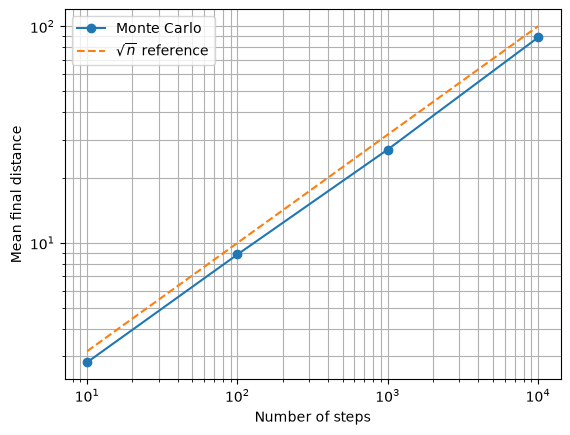

In [16]:
import matplotlib.pyplot as plt

means = []

for n in step_counts:
    distances = simulate_walks(n, num_trials)
    means.append(np.mean(distances))

plt.loglog(step_counts, means, "o-", label="Monte Carlo")
plt.loglog(
    step_counts,
    np.sqrt(np.array(step_counts)),
    "--",
    label=r"$\sqrt{n}$ reference"
)

plt.xlabel("Number of steps")
plt.ylabel("Mean final distance")
plt.legend()
plt.grid(True, which="both")
plt.show()